# Wetland Mapping with TropWet: Composite and Endmembers

*Section 13 — Case study: wetland mapping (TropWet), notebook 1 of 6.* Previous: `12_downloading_data/08_icepyx_download_icesat2`. Next: `02_unmixing_and_classification`.

Wetlands are hard to map with a per-pixel classifier: at 30 m most wetland pixels are a mixture of open water, emergent vegetation and bare sand or mud, and the mixture changes as floods and tides come and go. The **Tropical Wetland (TropWet) mapping tool** (Hardy, Oakes and Ettritch, 2020) avoids training data altogether: it unmixes every Landsat pixel into **water**, **vegetation** and **sand** fractions, using endmembers chosen automatically with NDVI and MNDWI thresholds, and classifies the fractions with simple rules.

The rsgispy guide [Spectral unmixing for wetland mapping (TropWet)](https://rsgispy.readthedocs.io/en/latest/guides/spectral_unmixing.html) explains the method and runs it as one script on the Landsat images of the northern **Rufiji delta**, Tanzania (the images of the change detection notebooks in section 6). This case study builds on the guide. It runs the same steps one at a time, so you can look at every intermediate result, and then follows up the problems the guide points out:

- **this notebook** builds the composite, looks at where the endmember thresholds sit in the NDVI / MNDWI feature space, and finds that the automatically selected "sand" endmember is really wet mud; it then derives a second, brighter sand endmember;
- **notebook 02** unmixes the composite with both endmember sets, compares their errors, combines them per pixel (a simple multiple endmember, MESMA, approach), and tests how sensitive the wetland areas are to the class thresholds;
- **notebook 03** classifies each date on its own, maps the wetland change between 1997 and 2018, and checks the classes against reference polygons;
- **notebook 04** finds endmembers in the image itself (HySime, HFC, ATGP, VCA, N-FINDR and the Pixel Purity Index) and compares the results with the published method;
- **notebook 05** builds a spectral library from the pure pixels, prunes it (EAR, MASA, CoB, IES), runs MESMA and AutoMCU, and compares the results with the published method;
- **notebook 06** measures how sensitive the published method is to the endmember selection, with a bootstrap of the pure pixels and a one-at-a-time and Sobol sensitivity analysis of the selection rules.

**You will learn:**
- how to subset and reorder the bands of two Landsat sensors so they can be combined (`subset_bbox`, `select_img_bands`);
- how to make a per-pixel median composite with `create_percentile_composite`;
- how to draw the NDVI / MNDWI feature space with `plot_2d_img_histogram` and see where the TropWet endmember rules select pixels;
- how to select pure pixels with `band_maths` and average their spectra into endmembers (`extract_img_pxl_vals_in_msk`, `plot_endmembers`, `write_endmembers_df`);
- how to check an automatically selected endmember and replace it with a better one.

**Before you start:** read the [TropWet guide](https://rsgispy.readthedocs.io/en/latest/guides/spectral_unmixing.html) for the method and its thresholds; notebook `07_spectral_analysis/03_spectral_unmixing` introduces linear unmixing with a hyperspectral image.

**Data:** `../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 5 TM, 16 July 1997) and `../data/chg_data/LS8_20180608_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 8 OLI, 8 June 2018): cloud-masked surface reflectance x **1000**, no data 0. Outputs are written to `outputs/inputs/` and `outputs/endmembers/`.

**Run time:** < 1 minute.

## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook can be browsed online without having to run the notebook for it to make sense.

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_

## 1. Import Modules

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

import rsgispy
import rsgispy.imagespectral.endmembers as spec_em
from rsgispy.imagecalc.calcindices import calc_indices
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imagecalc.stats import count_pxls_of_val
from rsgispy.imageutils.bands import select_img_bands
from rsgispy.imageutils.colourtable import set_thematic_classes
from rsgispy.imageutils.composite import create_percentile_composite
from rsgispy.imageutils.sampling import extract_img_pxl_vals_in_msk
from rsgispy.imageutils.subsetting import subset_bbox
from rsgispy.mapping.layout import MapPanel, create_map_panels
from rsgispy.tools.plotting import plot_2d_img_histogram

## 2. Define Input Data and Directories

The Landsat images are surface reflectance x 1000, so `refl_scale = 1000` converts them to reflectance (0–1). TropWet needs six bands in the order Blue, Green, Red, NIR, SWIR1 and SWIR2: these are bands 1–6 of the Landsat 5 TM image (TM band 6, thermal, is not in the file) and bands 2–7 of the Landsat 8 OLI image (band 1 is the coastal aerosol band). The subset is the 27 x 23 km area of the northern delta used in the guide and in the change detection notebooks.

In [2]:
chg_dir = "../data/chg_data"

in_dir = os.path.join("outputs", "inputs")
em_dir = os.path.join("outputs", "endmembers")
for out_path in (in_dir, em_dir):
    os.makedirs(out_path, exist_ok=True)

refl_scale = 1000.0  # the images are reflectance x 1000
band_names = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"]
# Landsat 8 OLI band centres (nm), for the x axis of the spectra plots.
wavelengths = [482, 561, 655, 865, 1609, 2201]

# min x, max x, min y, max y (UTM zone 37S, WGS84).
sub_bbox = (523000, 550000, -877000, -854000)

# Year: (file name prefix, the bands Blue, Green, Red, NIR, SWIR1, SWIR2).
scenes = {
    "1997": ("LS5TM_19970716", [1, 2, 3, 4, 5, 6]),
    "2018": ("LS8_20180608", [2, 3, 4, 5, 6, 7]),
}

## 3. Prepare the Reflectance Images

### 3.1 A function to tidy the reflectance

The unmixing functions skip every pixel with a band value `<= 0`. Dark water often has SWIR reflectance of zero after atmospheric correction, so without care the lakes and channels would become no data holes. `prep_refl` (the same function as in the guide) keeps 0 as no data where any band is 0, and clips the valid values to at least 1 (0.001 reflectance). It also sets the band names.

`band_maths` evaluates one expression per output band, separated by commas. `vld = ...` assigns a variable in the first expression that the later bands reuse.

In [3]:
def prep_refl(in_img, out_img):
    """No data (0) where any band is 0; valid values clipped to >= 1."""
    defs = [BandDefn(f"b{idx}", in_img, idx) for idx in range(1, 7)]
    vld = " && ".join(f"b{idx} != 0" for idx in range(1, 7))
    exp = ", ".join(
        [f"(vld = {vld}) ? max(b1, 1) : 0"]
        + [f"vld ? max(b{idx}, 1) : 0" for idx in range(2, 7)]
    )
    band_maths(
        out_img,
        exp,
        defs,
        datatype=rsgispy.TYPE_16UINT,
        band_names=band_names,
        no_data_val=0,
        use_pbar=False,
    )
    return out_img

### 3.2 Subset, select the bands and tidy each image

In [4]:
sref_imgs = {}
for year, (name, bands) in scenes.items():
    sub_img = os.path.join(in_dir, f"{name}_sub.tif")
    subset_bbox(
        os.path.join(chg_dir, f"{name}_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif"),
        sub_img,
        *sub_bbox,
        calc_stats=False,
        use_pbar=False,
    )
    sel_img = os.path.join(in_dir, f"{name}_6bands.tif")
    select_img_bands(sub_img, sel_img, bands, calc_stats=False, use_pbar=False)
    sref_imgs[year] = prep_refl(sel_img, os.path.join(in_dir, f"sref_{year}.tif"))
sref_imgs

{'1997': 'outputs/inputs/sref_1997.tif',
 '2018': 'outputs/inputs/sref_2018.tif'}

### 3.3 Look at the two images

NIR, SWIR1 and Red as red, green and blue show vegetation in green, water in dark blue and bare surfaces in pink or brown. The black area in the south-east of the 2018 image is masked cloud.

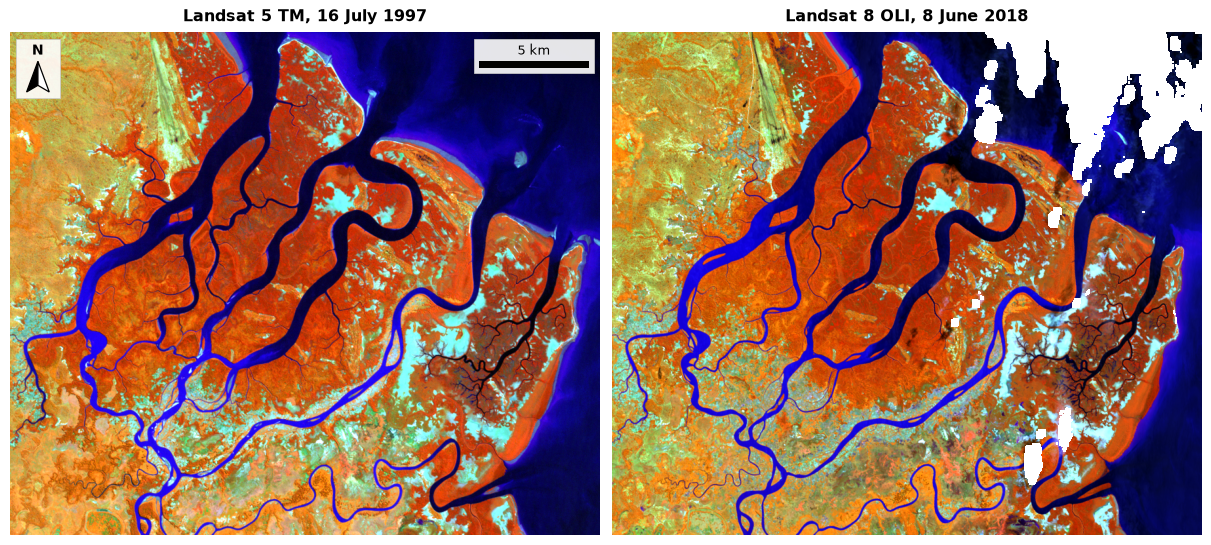

In [5]:
fig, axs = create_map_panels(
    [
        MapPanel("rgb", sref_imgs["1997"], bands=[4, 5, 3], title="Landsat 5 TM, 16 July 1997"),
        MapPanel("rgb", sref_imgs["2018"], bands=[4, 5, 3], title="Landsat 8 OLI, 8 June 2018"),
    ],
    figsize=(12, 6),
)

## 4. Median Composite

TropWet works on a median composite of all the cloud-free observations in a period, which removes clouds and shadows the cloud mask missed. `create_percentile_composite` calculates the per-pixel, per-band median (the 50th percentile) of the valid observations, so the pixels cloudy in 2018 still get a value from 1997.

**Note:** two dates 21 years apart are not a season of observations. With two values the median is their mean, so the composite mixes two states of the delta (and two sensors). It is fine for choosing endmembers, which is what it is used for here, but notebook 03 classifies each date on its own. With your own data, composite all the cloud-free images within one season.

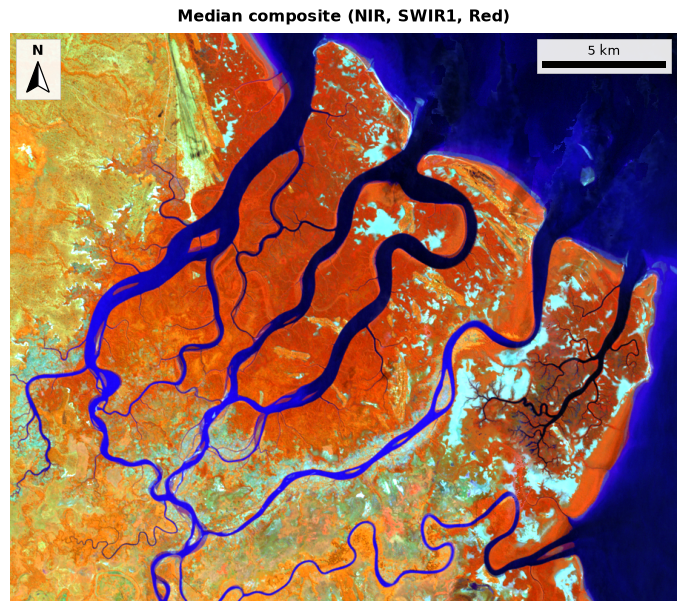

In [6]:
median_img = os.path.join(in_dir, "sref_median.tif")
create_percentile_composite(
    list(sref_imgs.values()),
    median_img,
    [50],
    no_data_val=0,
    datatype=rsgispy.TYPE_16UINT,  # rounded to integers
    use_pbar=False,
)
comp_img = prep_refl(median_img, os.path.join(in_dir, "sref_composite.tif"))

fig, axs = create_map_panels(
    [MapPanel("rgb", comp_img, bands=[4, 5, 3], title="Median composite (NIR, SWIR1, Red)")],
    figsize=(7, 6),
)

## 5. NDVI, MNDWI and the Feature Space

### 5.1 Calculate the indices

`calc_indices` calculates both indices in one pass: NDVI = (NIR − Red) / (NIR + Red) and MNDWI = (Green − SWIR1) / (Green + SWIR1). `band_names` maps the image bands to the names the index registry uses, `in_gain` converts the values to reflectance, and the output no data value is −999.

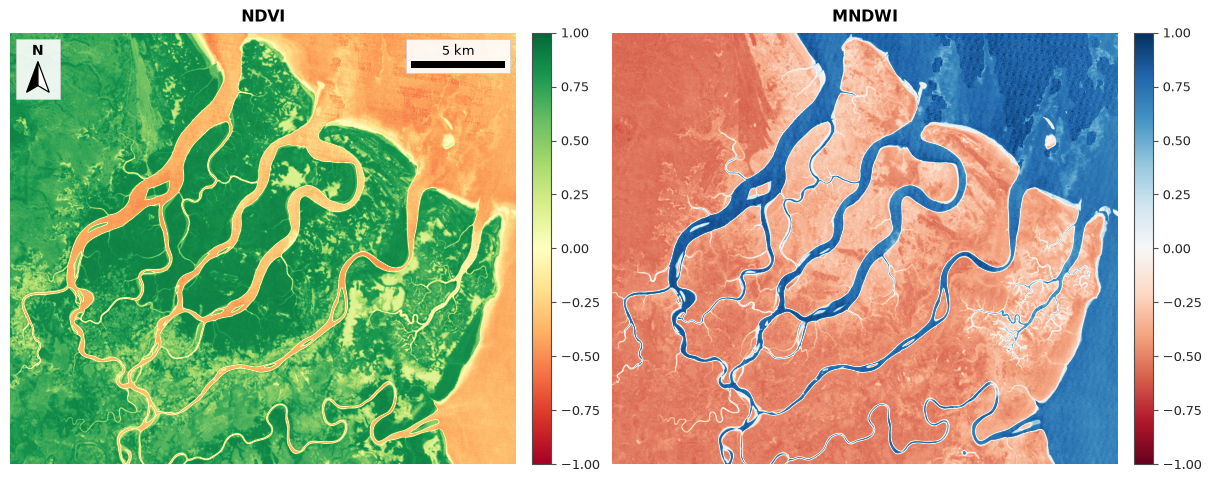

In [7]:
idx_img = os.path.join(in_dir, "composite_indices.tif")
calc_indices(
    comp_img,
    idx_img,
    band_names={1: "blue", 2: "green", 3: "red", 4: "nir", 5: "swir1", 6: "swir2"},
    indices=["NDVI", "MNDWI"],
    in_gain=refl_scale,
    no_data_val=0,
    use_pbar=False,
)

fig, axs = create_map_panels(
    [
        MapPanel("cmap", idx_img, bands=1, title="NDVI", cmap_name="RdYlGn",
                 vmin=-1, vmax=1, show_colour_bar=True),
        MapPanel("cmap", idx_img, bands=2, title="MNDWI", cmap_name="RdBu",
                 vmin=-1, vmax=1, show_colour_bar=True),
    ],
    figsize=(12, 5),
)

### 5.2 Where do the endmember rules sit in the feature space?

The TropWet endmembers are chosen with three rules (Hardy et al., 2020, Table 1):

| Endmember | Pure pixel rule |
| --- | --- |
| Water | MNDWI > 0.5 |
| Vegetation | NDVI > 0.7 |
| Sand | 0.16 < NDVI < 0.17 and −0.28 < MNDWI < 0.26 |

In the NDVI / MNDWI feature space, water, vegetation and bare surfaces are the corners of a triangle of mixtures. `plot_2d_img_histogram` counts the 2D histogram of the two index bands block by block (pixels outside `x_range` and `y_range`, such as the no data value −999, are not counted) and plots it on a log scale. The function `draw_rules` below adds the three rules as rectangles, so you can see which part of the data cloud each rule takes.

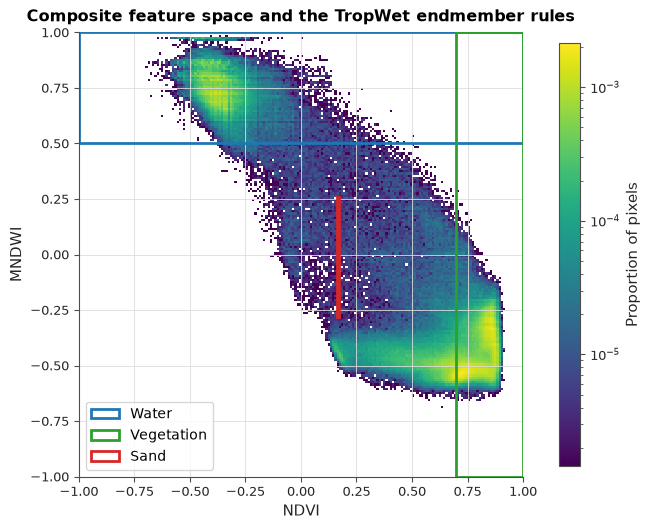

In [8]:
tropwet_rules = {
    # name: (NDVI min, NDVI max, MNDWI min, MNDWI max, colour)
    "Water": (-1.0, 1.0, 0.5, 1.0, "#1F77B4"),
    "Vegetation": (0.7, 1.0, -1.0, 1.0, "#2CA02C"),
    "Sand": (0.16, 0.17, -0.28, 0.26, "#D62728"),
}


def draw_rules(ax, rules):
    """Draw endmember rules (NDVI / MNDWI rectangles) on a feature space plot."""
    for name, (x0, x1, y0, y1, colour) in rules.items():
        ax.add_patch(
            Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=colour,
                      linewidth=2, label=name)
        )
    ax.legend(loc="lower left")


fig, ax = plot_2d_img_histogram(
    idx_img,
    x_band=1,
    y_band=2,
    bins=200,
    x_range=(-1, 1),
    y_range=(-1, 1),
    x_label="NDVI",
    y_label="MNDWI",
    title="Composite feature space and the TropWet endmember rules",
    use_pbar=False,
)
draw_rules(ax, tropwet_rules)

The water and vegetation rules each take a large part of a corner of the triangle. The sand rule is a thin sliver (one hundredth of an NDVI unit wide) in the middle of the lower edge, and there is no obvious "bare" corner here: the delta is mostly mangroves, channels and the sea, with farmland inland.

## 6. Select the Pure Pixels

The three rules are written as one `band_maths` expression: 1 = water, 2 = vegetation, 3 = sand, 0 = not pure (water is tested first). `count_pxls_of_val` counts the pixels selected for each endmember. `set_thematic_classes` stores class names and colours in the image so it can be mapped.

In [9]:
def select_pure_pxls(rules, out_img):
    """Mask of pixels passing each rule: 1, 2, 3, ... in the order of ``rules``."""
    exp, close = "", ""
    for val, (x0, x1, y0, y1, _) in enumerate(rules.values(), start=1):
        # Limits of -1 or 1 are the ends of the index range: no test needed.
        parts = [test for test, lim in ((f"ndvi > {x0}", x0), (f"ndvi < {x1}", x1),
                                         (f"mndwi > {y0}", y0), (f"mndwi < {y1}", y1))
                 if abs(lim) < 1]
        rule = " && ".join(parts)
        exp += f"({rule}) ? {val} : ("
        close += ")"
    band_maths(
        out_img,
        "ndvi < -1 ? 0 : " + exp + "0" + close,  # -999 is no data
        [BandDefn("ndvi", idx_img, 1), BandDefn("mndwi", idx_img, 2)],
        datatype=rsgispy.TYPE_8UINT,
        use_pbar=False,
    )
    set_thematic_classes(
        out_img, {val: (name, rule[4]) for val, (name, rule) in enumerate(rules.items(), start=1)}
    )
    counts = count_pxls_of_val(out_img, list(range(1, len(rules) + 1)), img_band=1, use_pbar=False)
    return dict(zip(rules, counts.tolist()))


em_msk_img = os.path.join(em_dir, "tropwet_pure_pxls.tif")
em_counts = select_pure_pxls(tropwet_rules, em_msk_img)
print("Pure pixels per endmember:", em_counts)

Pure pixels per endmember: {'Water': 179686, 'Vegetation': 325297, 'Sand': 181}


Hundreds of thousands of water and vegetation pixels, but only a couple of hundred sand pixels. A mean of the spectra of so few pixels is still usable, but it depends heavily on *which* pixels they are, so look at where they are. Zooming in on the river mouths shows them as a thin red line along the river banks, between the water and the mangroves:

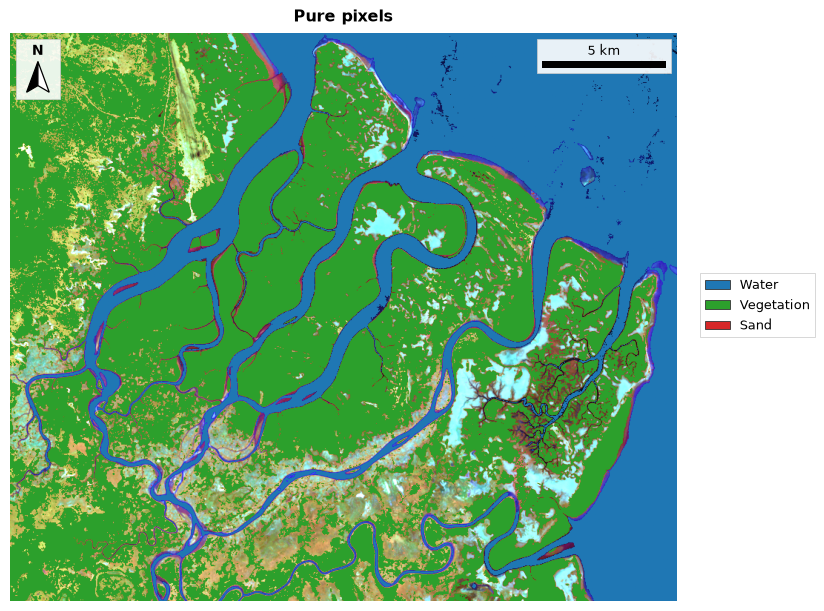

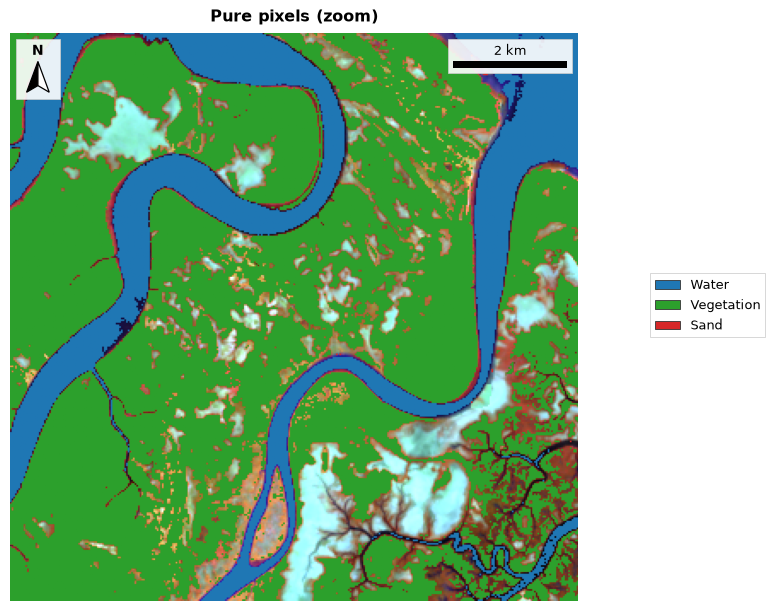

In [10]:
fig, axs = create_map_panels(
    [MapPanel("thematic", em_msk_img, base_img=comp_img, base_bands=(4, 5, 3),
              title="Pure pixels")],
    figsize=(7, 6),
)
# The same, zoomed in on the main river mouths.
fig, axs = create_map_panels(
    [MapPanel("thematic", em_msk_img, base_img=comp_img, base_bands=(4, 5, 3),
              title="Pure pixels (zoom)")],
    bbox=(536000, 546000, -870000, -860000),
    figsize=(7, 6),
)

## 7. The TropWet Endmembers

Each endmember is the mean spectrum of its pure pixels (the "spectral averaging" of the Earth Engine implementation). `extract_img_pxl_vals_in_msk` reads the six bands of the pixels with one mask value. The table has the bands as rows and the endmembers as columns, in the units of the image (reflectance x 1000).

In [11]:
def mean_spectra(msk_img, names):
    """Mean composite spectrum of the pixels of each mask value (1, 2, ...)."""
    return pd.DataFrame(
        {
            name: extract_img_pxl_vals_in_msk(
                comp_img, list(range(1, 7)), msk_img, val, no_data_val=0, use_pbar=False
            ).mean(axis=0)
            for val, name in enumerate(names, start=1)
        },
        index=pd.Index(band_names, name="band"),
    )


em_tropwet_df = mean_spectra(em_msk_img, tropwet_rules)
em_tropwet_df.round(0)

,Water,Vegetation,Sand
band,,,
Blue,58.0,25.0,63.0
Green,80.0,47.0,97.0
Red,64.0,34.0,104.0
NIR,32.0,317.0,146.0
SWIR1,12.0,123.0,103.0
SWIR2,11.0,55.0,66.0


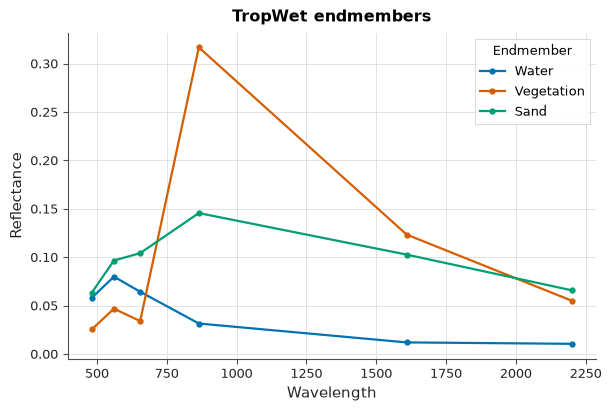

In [12]:
fig, ax = spec_em.plot_endmembers(
    em_tropwet_df, gain=refl_scale, wavelengths=wavelengths,
    plot_title="TropWet endmembers", figsize=(6, 4),
)

Water is dark and falls into the SWIR, but it is turbid (green reflectance 0.08): the delta's water carries a lot of sediment. Vegetation has the red edge of the mangroves. The "sand" is dark (0.06–0.15) and not much brighter than the water in the visible bands: these are not dry sand pixels but wet mud and sand at the water's edge, partly covered by water.

## 8. Checking the Sand Endmember

### 8.1 Is there brighter bare ground in the composite?

An endmember set should enclose the data: every pixel should be (close to) a mixture of the endmembers. If a surface is brighter than every endmember, no mixture with fractions between 0 and 1 can reach it. Compare the SWIR1 reflectance of the sand pixels with that of all the low-NDVI, dry pixels of the composite (NDVI between 0.05 and 0.2, MNDWI below −0.1: little vegetation and no water):

Pure pixels per endmember: {'Water': 179686, 'Vegetation': 325297, 'Sand': 6364}


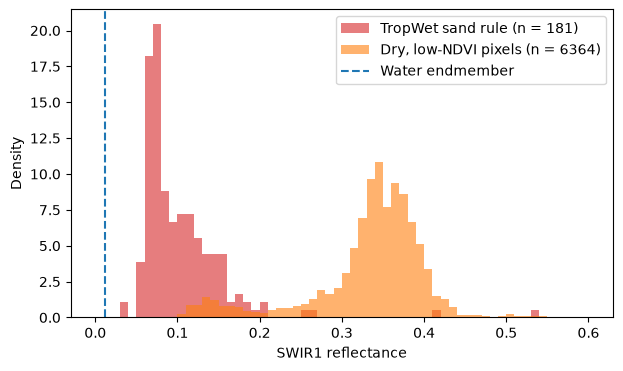

,TropWet sand rule,"Dry, low-NDVI pixels"
p10,0.062,0.239
median,0.086,0.346
p90,0.154,0.396


In [13]:
bright_rules = {
    "Water": tropwet_rules["Water"],
    "Vegetation": tropwet_rules["Vegetation"],
    "Sand": (0.05, 0.2, -1.0, -0.1, "#FF7F0E"),
}
bright_msk_img = os.path.join(em_dir, "bright_sand_pure_pxls.tif")
bright_counts = select_pure_pxls(bright_rules, bright_msk_img)
print("Pure pixels per endmember:", bright_counts)

swir1_vals = {
    "TropWet sand rule": extract_img_pxl_vals_in_msk(
        comp_img, [5], em_msk_img, 3, no_data_val=0, use_pbar=False)[:, 0],
    "Dry, low-NDVI pixels": extract_img_pxl_vals_in_msk(
        comp_img, [5], bright_msk_img, 3, no_data_val=0, use_pbar=False)[:, 0],
}
fig, ax = plt.subplots(figsize=(7, 4))
for (label, vals), colour in zip(swir1_vals.items(), ["tab:red", "tab:orange"]):
    ax.hist(vals / refl_scale, bins=60, range=(0, 0.6), density=True, alpha=0.6,
            color=colour, label=f"{label} (n = {vals.size})")
ax.axvline(em_tropwet_df.loc["SWIR1", "Water"] / refl_scale, color="tab:blue", ls="--",
           label="Water endmember")
ax.set_xlabel("SWIR1 reflectance")
ax.set_ylabel("Density")
ax.legend()
plt.show()

pd.DataFrame({k: np.percentile(v / refl_scale, [10, 50, 90]) for k, v in swir1_vals.items()},
             index=["p10", "median", "p90"]).round(3)

The dry, low-NDVI pixels (bare fields, salt flats and the bare areas between the mangroves) are much brighter in the SWIR than the TropWet sand pixels, and there are thousands of them. With the TropWet sand endmember, these surfaces are outside the triangle of the endmembers, and notebook 02 shows that they get the largest unmixing errors (as the guide found for the Dry Sparse Vegetation class).

The sand rule was calibrated on the Barotse floodplain, Zambia, where large areas of dry sand meet the narrow NDVI window. In a mangrove delta, the same window catches wet mud instead. This is the kind of check the guide recommends before trusting the maps.

### 8.2 A brighter sand endmember

The second endmember set keeps the TropWet water and vegetation endmembers and replaces the sand endmember with the mean of the dry, low-NDVI pixels. The plot shows the new rule (orange) on the feature space.

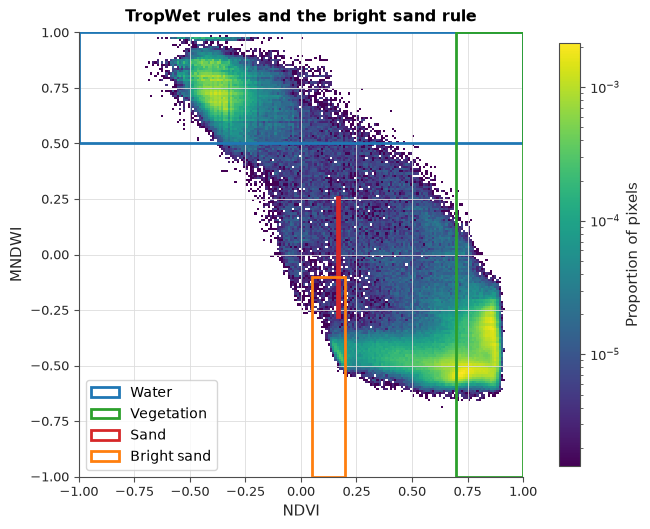

In [14]:
fig, ax = plot_2d_img_histogram(
    idx_img, x_band=1, y_band=2, bins=200, x_range=(-1, 1), y_range=(-1, 1),
    x_label="NDVI", y_label="MNDWI", title="TropWet rules and the bright sand rule", use_pbar=False,
)
draw_rules(ax, {**tropwet_rules, "Bright sand": bright_rules["Sand"]})

In [15]:
em_bright_df = em_tropwet_df.copy()
em_bright_df["Sand"] = mean_spectra(bright_msk_img, bright_rules)["Sand"]
em_bright_df.round(0)

,Water,Vegetation,Sand
band,,,
Blue,58.0,25.0,92.0
Green,80.0,47.0,137.0
Red,64.0,34.0,170.0
NIR,32.0,317.0,239.0
SWIR1,12.0,123.0,333.0
SWIR2,11.0,55.0,273.0


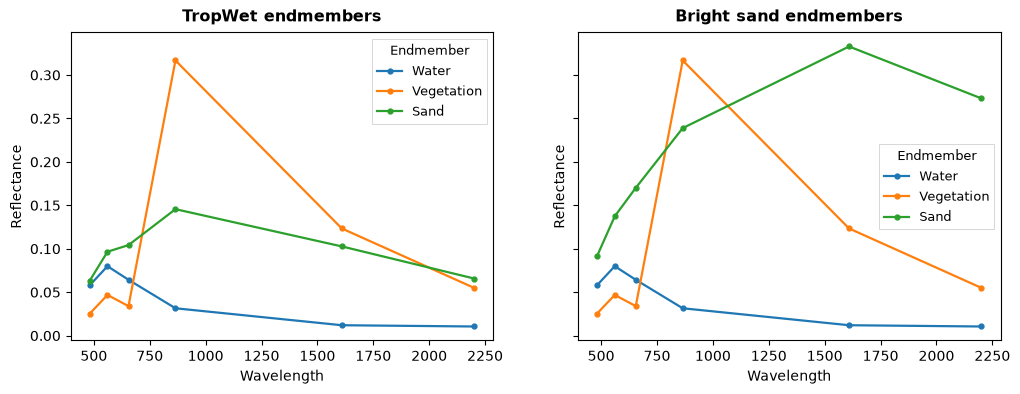

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
spec_em.plot_endmembers(em_tropwet_df, gain=refl_scale, wavelengths=wavelengths,
                        plot_title="TropWet endmembers", ax=axs[0])
spec_em.plot_endmembers(em_bright_df, gain=refl_scale, wavelengths=wavelengths,
                        plot_title="Bright sand endmembers", ax=axs[1])
plt.show()

The bright sand endmember is flat-to-rising into the SWIR (SWIR1 reflectance about 0.33), the typical shape of dry soil and sand, and is much brighter than the wet mud endmember.

Neither set is "right". The TropWet sand endmember describes the wet mud banks and beaches well, while the bright sand endmember describes the dry fields and salt flats. Notebook 02 unmixes with both, compares the errors and keeps, per pixel, whichever set fits best.

## 9. Save the Endmembers

`write_endmembers_df` writes each table as a CSV file, which notebooks 02 and 03 read back with `read_endmembers_df`.

In [17]:
em_files = {
    "tropwet": os.path.join(em_dir, "endmembers_tropwet.csv"),
    "bright": os.path.join(em_dir, "endmembers_bright_sand.csv"),
}
spec_em.write_endmembers_df(em_tropwet_df, em_files["tropwet"])
spec_em.write_endmembers_df(em_bright_df, em_files["bright"])
em_files

{'tropwet': 'outputs/endmembers/endmembers_tropwet.csv',
 'bright': 'outputs/endmembers/endmembers_bright_sand.csv'}

## 10. Summary

- The two Landsat sensors were brought to the same six bands and combined into a median composite.
- The TropWet rules found plenty of pure water and vegetation pixels, but only a few hundred "sand" pixels, and those are wet mud at the water's edge.
- The composite contains much brighter, dry bare surfaces, so a second endmember set with a bright sand endmember was derived.

Next, notebook `02_unmixing_and_classification` unmixes the composite with both endmember sets.

**Reference:** Hardy, A., Oakes, G., Ettritch, G. (2020). Tropical Wetland (TropWet) Mapping Tool: The Automatic Detection of Open and Vegetated Waterbodies in Google Earth Engine for Tropical Wetlands. *Remote Sensing*, 12(7), 1182. https://doi.org/10.3390/rs12071182

Landsat data courtesy of the U.S. Geological Survey.